$\large \color{royalblue} {\textbf{OCOM5100M - Programming for Data Science}}$

**Student ID:** 202144129


$\large \color{royalblue} {\textbf{Summative Assessment 2}}$



### Data Analysis and Modelling Project

This assessment consists of two parts that evaluate your practical skills in programming for data science, across Weeks 1-6 of the module.

- **Part 1: Data Analysis Project** (32 marks)  
- **Part 2: Machine Learning Pipeline** (32 marks)
- **Process Log** (12 marks)
- **Report Quality** (4 marks)


## Assessment Overview

### Part 1 – Data Analysis Project (32 marks)

| Component | Marks |
|---|---|
| Project Aim and Dataset description | 10 |
| Code quality and workflow | 12 |
| Objectives analysis | 6 |
| Insights and reflection | 4 |

### Part 2 – Machine Learning Pipeline (32 marks)

| Component | Marks |
|---|---|
| Preprocessing and pipelines | 10 |
| Baseline model training | 4 |
| Cross-validation | 6 |
| Hyperparameter tuning | 6 |
| Final Model Evaluation and Justification | 6 |


---
### Using this Notebook Template

Please use this notebook as a template for your project file.
Replace the placeholder text in each section with your own work.
Do not leave template guidance in your final submission.

**Do not delete or rename the main blue assessment headings.** Your submitted notebook must have the same overall structure as this template.

---

### Submission requirements

You must submit:
- This **Jupyter Notebook (`P4DS_A2_Data_Analysis_Project.ipynb`)** with all cells executed and outputs visible

Before you submit:
- Ensure the notebook runs from top to bottom without errors using `Kernel → Restart & Run All`
- Delete all template placeholder and instruction text from markdown cells
- Do not delete or rename the main blue assessment headings. You may add informative subheadings within each section.
- Do not submit extra files unless explicitly requested

---


### Dataset selection

#### Part 1 (Exploratory Data Analysis)

For Part 1, you must choose your own dataset, and it must be publicly available and suitable for exploratory data analysis. Recommended sources:

- Kaggle – https://www.kaggle.com/datasets  
- UCI Machine Learning Repository – https://archive.ics.uci.edu/ml/index.php  
- scikit-learn sample datasets – https://scikit-learn.org/stable/datasets.html  
- Open data portals and APIs (e.g. government, WHO, World Bank)

**You may use scikit-learn only to load a built-in dataset (e.g. `sklearn.datasets`). You must not use the library for any other part of your analysis in this section**, no preprocessing, transformations, or statistical functions from scikit-learn. Part 1 should otherwise rely on core Python, pandas, and a visualisation library only; the full scikit-learn toolkit is reserved for Part 2.


#### Part 2 (Modelling)

For Part 2, you will work with a fixed dataset provided by the module team. This dataset will support a binary classification problem, contain a mixture of numerical and categorical features, and include a clearly defined target variable.




$\large \color{royalblue} {\textbf{Part 1: Data Analysis Project (32 marks)}}$



$\large \color{royalblue} {\textbf{Project Title}}$


Salary and Work-Mode Patterns in US AI and Data Roles, 2023–2025

$\large \color{royalblue} {\textbf{Section 1.1 – Project Aim and Data Description (10 marks)}}$


**Aim:** Examine recent salary patterns and working arrangements among full-time AI/ML/data professionals employed by US-based companies between 2023 and 2025. 

**Objective 1:** Quantify and compare the distribution of `salary_in_usd` across experience levels and work years in the full-time US sample, using group sizes, medians, and measures of spread.

**Objective 2:** Measure how work-mode composition changes from 2023 to 2025 and examine salary differences, particularly between on-site and remote work, while accounting for experience-level composition, in the full-time US sample.

This analysis examines salary and work-mode patterns in full-time AI-related roles between 2023 and 2025.
| Dataset | Version | License | Source | Last updated | Download Date |
|:--:|:--:|:---:|:--:|:--:|:--:|
|[ai_jobs_salaries_clean.csv](https://www.kaggle.com/datasets/debayank2024/ai-impact-on-jobs-and-salaries-2020-2026?resource=download)|Version 1 — Initial release|Attribution 4.0 International (CC BY 4.0)|[foorilla/ai-jobs-net-salaries](https://github.com/foorilla/ai-jobs-net-salaries)|2026-08-17|2026-09-29|
* **Collection and provenance:**
The dataset contains weekly snapshots of AI/ML/Data Science salary data collected through the voluntary survey at [aijobs.net/salaries](https://aijobs.net/salaries/). The data are not weighted to the US labour market and were not collected by an official government body, so conclusions describe observed records from this anonymous, voluntary survey rather than the full population of US AI/data professionals; this may introduce self-selection bias.
* **Dataset contents:**
The raw file covers 2020 to 2025 across 97 company locations, with most records from US-based companies. The analysis restricts to `work_year >= 2023` and `company_location == "US"`. The dataset has 17 columns, including `work_year`, `experience_level`, `salary_in_usd`, `remote_ratio` and `work_mode`, which are relevant to the objectives. Three sample sizes must not be confused: 71,913 rows in the raw file, 59,181 in the pre-employment-type scope after the year and location filters, and 58,663 in the final analytical sample after restricting to full-time records.
* **Data quality:**
No duplicate rows were found. In the pre-employment-type scope, 1,654 records are flagged as potential salary outliers (1,652 in the final sample), which may affect the mean; 2023 has far fewer records than 2024 and 2025. Only 21 pre-scope and 20 final-sample records are `work_mode='Hybrid'`, so that group is very small. Missing values appear only in `isco_group_hint`, which is not used in this analysis. All records use `salary_in_usd` as a standardised salary measure, making it suitable for comparing different work arrangements across locations. The dataset has no unique employee or vacancy identifier, so rows are not treated as unique people or unique job postings.
* **Suitability and limitations:**
The dataset supports Objective 1 with many observations and USD-standardised salaries. Because the sample is restricted to US companies and full-time records, the findings may not generalise to other regions, to part-time, contract or freelance work, or to the full US AI/data workforce. This project is descriptive: it quantifies distributions, compositions and associations in the recorded sample, but does not establish that work year, experience level or work mode caused the observed salary differences.



$\large \color{royalblue} {\textbf{Section 1.2 – Exploratory Data Analysis and Program Code (12 marks)}}$


In [1]:
# code cell
import pandas as pd

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 140)
file_path = "ai_jobs_salaries_clean.csv"
ai_jobs_raw = pd.read_csv(file_path)
# Shape and columns
print("Loaded:", file_path)
print("Shape:", ai_jobs_raw.shape)


Loaded: ai_jobs_salaries_clean.csv
Shape: (71913, 17)


Loaded 71,913 rows × 17 columns from assessment/ai_jobs_salaries_clean.csv. Next: confirm column types before relying on any field.

In [2]:
print("Columns and dtypes:")
print(ai_jobs_raw.dtypes)

audit_columns = ["work_year", "experience_level", "employment_type", "job_title",
              "salary", "salary_currency", "salary_in_usd",
              "employee_residence", "remote_ratio",
              "company_location", "company_size"]
print("\nFirst 3 rows:")
print(ai_jobs_raw[audit_columns].head(3))

Columns and dtypes:
work_year                 int64
experience_level            str
employment_type             str
job_title                   str
salary                    int64
salary_currency             str
salary_in_usd             int64
employee_residence          str
remote_ratio              int64
company_location            str
company_size                str
experience_level_label      str
employment_type_label       str
work_mode                   str
salary_outlier_flag        bool
role_family                 str
isco_group_hint             str
dtype: object

First 3 rows:
   work_year experience_level employment_type       job_title  salary salary_currency  salary_in_usd employee_residence  remote_ratio  \
0       2025               EX              FT    Head of Data  348516             USD         348516                 US             0   
1       2025               EX              FT    Head of Data  232344             USD         232344                 US             0

17 columns: 4 numeric (`work_year`, `salary`, `salary_in_usd`, `remote_ratio`), 12 string, 1 boolean (`salary_outlier_flag`). `work_mode` is validated below; `role_family` and `isco_group_hint` are excluded because their derivation is undocumented and neither is required for the objectives.

In [3]:
# Check for missing and duplicate values
# Quality audit: missingness and duplicate rows. isco_group_hint is the only
# column expected to have gaps; everything else should be complete. We also
# check duplicates on a plausible identity key, not just full-row repeats,
# because exact-row duplicates were already verified to be zero in the plan.

missing = (ai_jobs_raw.isna().sum().to_frame(name="missing_rows"))
missing["missing_percentage"] = (missing["missing_rows"] / len(ai_jobs_raw) *100).round(2) 
print("Missing values:\n", missing[missing["missing_rows"] > 0])
duplicates = ai_jobs_raw.duplicated().sum()
print("\nDuplicate rows:", duplicates)
key_columns = ["work_year", "job_title", "salary_in_usd",
            "employee_residence", "company_location"]
print(f"Duplicate rows on {key_columns}:", ai_jobs_raw.duplicated(subset=key_columns).sum())

Missing values:
                  missing_rows  missing_percentage
isco_group_hint         40540               56.37

Duplicate rows: 0
Duplicate rows on ['work_year', 'job_title', 'salary_in_usd', 'employee_residence', 'company_location']: 15963


Only `isco_group_hint` has gaps: 40,540 missing (56.4%); every other column is complete. There are no exact duplicate rows. Although 15,963 rows share the five-field key, this key is not a unique identifier, so these rows are not treated as confirmed duplicates.

In [4]:
# Low-cardinality categoricals should each use a closed, well-spelled set
# of values. Large unique counts or stray variants would distort every
# later group count.
print("Work year counts:")
print(ai_jobs_raw["work_year"].value_counts().sort_index())

for col in ["experience_level", "employment_type", "company_size", "work_mode", "remote_ratio"]:
    print(f"\n{col}:\n{ai_jobs_raw[col].value_counts()}")
    

# Derived *_label columns should agree 1:1 with their code counterparts.
print("\nexperience_level <-> experience_level_label:\n",)
print(pd.crosstab(ai_jobs_raw["experience_level"], ai_jobs_raw["experience_level_label"]))
print("\nemployment_type <-> employment_type_label:\n",)
print(pd.crosstab(ai_jobs_raw["employment_type"], ai_jobs_raw["employment_type_label"]))

# Geography: many unique countries. Show top entries + total count.
for  col in ["employee_residence", "company_location"]:
    print(f"\n[{col}] unique={ai_jobs_raw[col].nunique()}")
    print(ai_jobs_raw[col].value_counts().head(10))

# work_mode must agree 1:1 with remote_ratio — cross-tab as a check.
print("\nwork_mode <-> remote_ratio:")
print(pd.crosstab(ai_jobs_raw["work_mode"], ai_jobs_raw["remote_ratio"]))

Work year counts:
work_year
2020       75
2021      214
2022     1114
2023     4538
2024    27690
2025    38282
Name: count, dtype: int64

experience_level:
experience_level
SE    37702
MI    23395
EN     7975
EX     2841
Name: count, dtype: int64

employment_type:
employment_type
FT    71163
CT      383
PT      351
FL       16
Name: count, dtype: int64

company_size:
company_size
M    70110
L     1588
S      215
Name: count, dtype: int64

work_mode:
work_mode
On-site    54081
Remote     17505
Hybrid       327
Name: count, dtype: int64

remote_ratio:
remote_ratio
0      54081
100    17505
50       327
Name: count, dtype: int64

experience_level <-> experience_level_label:

experience_level_label  Entry-level  Executive-level  Mid-level  Senior-level
experience_level                                                             
EN                             7975                0          0             0
EX                                0             2841          0             0
MI    

Low-cardinality categoricals checked here use closed label sets (4 experience levels, 4 employment types, 3 company sizes, 3 work modes, 3 remote-ratio values). High-cardinality fields such as `job_title` (422 unique values) are not exhaustively validated, so label drift is not ruled out for them. The *_label columns and work_mode ↔ remote_ratio agree 1:1 with their code counterparts. Geography has 97 unique company_location and 104 unique employee_residence values; top entries are sensible country codes. Year coverage spans 2020–2025, but 2020–2022 contribute only 1,403 rows (1.95%), justifying the 2023–2025 restriction.

In [5]:
# Outcome-variable audit. Compute our own IQR rule and cross-check it
# against the uploader-supplied salary_outlier_flag column rather than
# trusting it blindly.

salary = ai_jobs_raw["salary_in_usd"]
print(salary.describe())
q1, q3 = salary.quantile([0.25, 0.75])
iqr = q3 - q1
lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
print(f"IQR rule bounds: {lower:.0f} to {upper:.0f}")

flag = ai_jobs_raw["salary_outlier_flag"]
print(f"\nOutlier flag value counts:\n", flag.value_counts())

outside_iqr = (salary < lower) | (salary > upper)
print(f"\nOutside IQR but not flagged: {((outside_iqr) & (~flag)).sum()}")
print(f"Flagged but inside IQR: {(flag & ~outside_iqr).sum()}")

# Look at the actual rows behind the extremes — by job, experience, year,
# employment type — to judge whether they are errors or genuine values.
cols_ext = ["work_year", "experience_level", "employment_type",
            "job_title", "salary_in_usd", "company_location",
            "company_size", "salary_outlier_flag"]
print("\nTop 5 highest salaries:")
print(ai_jobs_raw.nlargest(5, "salary_in_usd")[cols_ext].to_string(index=False))
print("\nTop 5 lowest salaries:")
print(ai_jobs_raw.nsmallest(5, "salary_in_usd")[cols_ext].to_string(index=False))
print("\nSample of flagged outlier rows (10):")
print(ai_jobs_raw[ai_jobs_raw["salary_outlier_flag"]].sample(10, random_state=1)[cols_ext].to_string(index=False))

count     71913.000000
mean     151161.252625
std       77329.594122
min       15000.000000
25%       96000.000000
50%      138750.000000
75%      190315.000000
max      800000.000000
Name: salary_in_usd, dtype: float64
IQR rule bounds: -45472 to 331788

Outlier flag value counts:
 salary_outlier_flag
False    70159
True      1754
Name: count, dtype: int64

Outside IQR but not flagged: 0
Flagged but inside IQR: 0

Top 5 highest salaries:
 work_year experience_level employment_type         job_title  salary_in_usd company_location company_size  salary_outlier_flag
      2025               SE              FT         Architect         800000               US            M                 True
      2025               SE              FT Software Engineer         800000               US            M                 True
      2024               MI              FT      AI Architect         800000               CA            M                 True
      2025               EN              FT   

`salary_in_usd` ranges from $15,000 to $800,000, with a median of $138,750. The outlier flag matches the IQR rule exactly. The inspected extremes span several experience levels and countries, with no evidence of recording errors, so they are retained and tested in Section 1.3.

In [6]:
# Build the analytical scope (2023-2025, US companies, valid salary) and
# report the row count after each step. "Valid salary" = positive, non-null
# salary_in_usd with a non-null currency code. Decisions on employment_type,
# outliers, and cross-border rows are made in the markdown cell below.

year_mask = ai_jobs_raw["work_year"].isin([2023, 2024, 2025])
us_mask = ai_jobs_raw["company_location"] == "US"
valid_salary = (ai_jobs_raw["salary_in_usd"].notna() & (ai_jobs_raw["salary_in_usd"] > 0) &
                ai_jobs_raw["salary_currency"].notna())

sample_flow = pd.DataFrame({
    "step": [
        "raw",
        "work_year in [2023, 2024, 2025]",
        "company_location == 'US'",
        "valid salary_in_usd (positive, currency present)",
    ],
    "rows": [
        len(ai_jobs_raw),
        year_mask.sum(),
        (year_mask & us_mask).sum(),
        (year_mask & us_mask & valid_salary).sum()
    ]
})
print(sample_flow)

# Analytical base for Sections 1.2 and 1.3. Use .copy() to avoid
# SettingWithCopyWarning when we add derived columns later.
ai_us_scope = ai_jobs_raw[year_mask & us_mask & valid_salary].copy()
print(f"Analytical base shape: {ai_us_scope.shape}")

                                               step   rows
0                                               raw  71913
1                   work_year in [2023, 2024, 2025]  70510
2                          company_location == 'US'  59181
3  valid salary_in_usd (positive, currency present)  59181
Analytical base shape: (59181, 17)


The four-step filter reduces 71,913 → 70,510 → 59,181 → 59,181. The US restriction removes 11,329 records after the year filter (the year filter itself removes 1,403 earlier records). The valid-salary step removes no rows, because every record already has a positive `salary_in_usd` with a non-null currency. The 59,181-row output is the **pre-employment-type scope**; the employment-type decision below reduces it to 58,663 rows, the **final analytical sample** used by all later code.

In [7]:
# Evidence for the three decisions recorded in the markdown cell below.

print("employment_type counts in scope:\n", ai_us_scope["employment_type"].value_counts())
ft_share = (ai_us_scope["employment_type"] == "FT").mean()
print(f"FT share: {ft_share:.4%}")

print("\nexperience_level counts in scope:\n", ai_us_scope["experience_level"].value_counts())
print("\nwork_mode counts in scope:\n", ai_us_scope["work_mode"].value_counts())
hybrid_n = int((ai_us_scope["work_mode"] == "Hybrid").sum())
print(f"Hybrid count: {hybrid_n}")

print("\ncompany_size counts in scope:\n", ai_us_scope["company_size"].value_counts())
cross_border = ai_us_scope[ai_us_scope["employee_residence"] != "US"]
cb_pct = len(cross_border) / len(ai_us_scope) * 100
print(f"\nCross-border (US co, non-US residence): {len(cross_border)} ({cb_pct:.2f}% of scope {len(ai_us_scope)})")

if len(cross_border) > 0:
    print(cross_border["employee_residence"].value_counts().head(5))

print(f"\nOutlier flag in scope:\n{ai_us_scope['salary_outlier_flag'].value_counts()}")
flag_share = ai_us_scope["salary_outlier_flag"].mean()
print(f"Flagged share: {flag_share:.4%}")


employment_type counts in scope:
 employment_type
FT    58663
PT      266
CT      252
Name: count, dtype: int64
FT share: 99.1247%

experience_level counts in scope:
 experience_level
SE    31630
MI    19008
EN     6011
EX     2532
Name: count, dtype: int64

work_mode counts in scope:
 work_mode
On-site    44842
Remote     14318
Hybrid        21
Name: count, dtype: int64
Hybrid count: 21

company_size counts in scope:
 company_size
M    58091
L     1057
S       33
Name: count, dtype: int64

Cross-border (US co, non-US residence): 34 (0.06% of scope 59181)
employee_residence
IN    5
PL    2
IT    2
CA    2
PT    2
Name: count, dtype: int64

Outlier flag in scope:
salary_outlier_flag
False    57527
True      1654
Name: count, dtype: int64
Flagged share: 2.7948%


**Decision 1** — employment type. Non-FT records (266 part-time, 252 contract) are 518 of 59,181 scope rows (0.88%). Hourly, contract and part-time roles are paid on different bases than salaried full-time positions, so mixing them would confound salary comparisons. The sample is restricted to `employment_type == "FT"` (58,663 rows) to improve salary comparability. Limitation: results describe full-time AI/ML/data professionals at US companies only.

**Decision 2** — salary outliers. `salary_outlier_flag` matches a manual IQR rule on `salary_in_usd` exactly. The 1,654 flagged scope rows are statistical extremes without evidence of data-entry errors, so they are retained; Section 1.3 recomputes medians without them as a check.

**Decision 3** — cross-border records. 34 of the 59,181 pre-full-time scope rows (0.057%) are US-company records with non-US residence (top: IN 5; PL/IT/CA/PT 2 each), of which 30 remain in `ai_us` after the full-time filter. They are retained; Section 1.3 reports a one-line sensitivity check excluding these 30 from the final sample.

In [8]:
# Apply the three decisions from the markdown cell above. Flip each flag
# to match the choice you wrote down.

keep_ft_only = True         # Decision 1: True keeps only employment_type == "FT"
drop_outliers = False       # Decision 2: True drops salary_outlier_flag rows
drop_cross_border = False   # Decision 3: True drops employee_residence != "US"

ai_us = ai_us_scope.copy()
if keep_ft_only:
    ai_us = ai_us[ai_us["employment_type"] == "FT"]
if drop_outliers:
    ai_us = ai_us[ai_us["salary_outlier_flag"] == False]
if drop_cross_border:
    ai_us = ai_us[ai_us["employee_residence"] == "US"]

print(f"Final analytical base shape: {ai_us.shape}")
print(f"Group sizes by experience_level * work_year:\n{ai_us.groupby(['experience_level', 'work_year']).size().unstack(fill_value=0)}")


Final analytical base shape: (58663, 17)
Group sizes by experience_level * work_year:
work_year         2023   2024   2025
experience_level                    
EN                 256   2623   2924
EX                 162    752   1614
MI                 795   7875  10165
SE                2558  12139  16800


Final analytical sample: 58,663 rows in `ai_us`. The group-size table confirms every year × experience cell has a defensible size (smallest 162 rows). The full-time filter shifts three pre-scope subgroups: hybrid 21 → 20, cross-border 34 → 30, and flagged outliers 1,654 → 1,652. Subsequent analysis reads from `ai_us`, not from `ai_us_scope` or `ai_jobs_raw`. Next: produce the reusable summary table for Section 1.3 to quote.

In [9]:
# Reusable summary that Section 1.3 will quote rather than recompute.

def q25(s): return s.quantile(0.25)
def q75(s): return s.quantile(0.75)

summary = (
    ai_us
    .groupby(["work_year", "experience_level"])
    .agg(
        n = ("salary_in_usd", "size"),
        mean = ("salary_in_usd", "mean"),
        median = ("salary_in_usd", "median"),
        q1_usd = ("salary_in_usd", q25),
        q3_usd = ("salary_in_usd", q75),
    ).round(0)
)
print(summary)

                                n      mean    median    q1_usd    q3_usd
work_year experience_level                                               
2023      EN                  256  102564.0   90000.0   65000.0  130001.0
          EX                  162  196064.0  193250.0  145000.0  238625.0
          MI                  795  136799.0  128000.0   93959.0  166000.0
          SE                 2558  169398.0  160374.0  125000.0  205496.0
2024      EN                 2623  109587.0   96800.0   71138.0  137750.0
          EX                  752  208251.0  200000.0  150000.0  251633.0
          MI                 7875  147840.0  134000.0   95000.0  181000.0
          SE                12139  176558.0  165000.0  123820.0  215166.0
2025      EN                 2924  108636.0   95510.0   70000.0  135000.0
          EX                 1614  206811.0  192300.0  146000.0  256000.0
          MI                10165  144788.0  130000.0   95000.0  177567.0
          SE                16800  176

Summary of the analytical sample by work year and experience level: medians rise with seniority (EN < MI < SE < EX), with mild year-on-year movement within each level. Section 1.3 quotes these numbers, plots them, and adds the work-mode comparison.

$\large \color{royalblue} {\textbf{Section 1.3 – Objectives Analysis (6 marks)}}$ 

Each objective below uses the final 58,663-row full-time US sample from `ai_us`. Headline pay differences are medians with the interquartile range (Q1-Q3); compositions are within-year percentages. Outlier and cross-border sensitivity checks are reported in-line. All salaries are annual USD.

$\large \color{royalblue} {\textbf{Objective 1 Analysis}}$ 

Salary (USD) by work year x experience level (US full-time, 2023-2025):
                                n      mean    median    q1_usd    q3_usd
work_year experience_level                                               
2023      EN                  256  102564.0   90000.0   65000.0  130001.0
          MI                  795  136799.0  128000.0   93959.0  166000.0
          SE                 2558  169398.0  160374.0  125000.0  205496.0
          EX                  162  196064.0  193250.0  145000.0  238625.0
2024      EN                 2623  109587.0   96800.0   71138.0  137750.0
          MI                 7875  147840.0  134000.0   95000.0  181000.0
          SE                12139  176558.0  165000.0  123820.0  215166.0
          EX                  752  208251.0  200000.0  150000.0  251633.0
2025      EN                 2924  108636.0   95510.0   70000.0  135000.0
          MI                10165  144788.0  130000.0   95000.0  177567.0
          SE                16800  17676

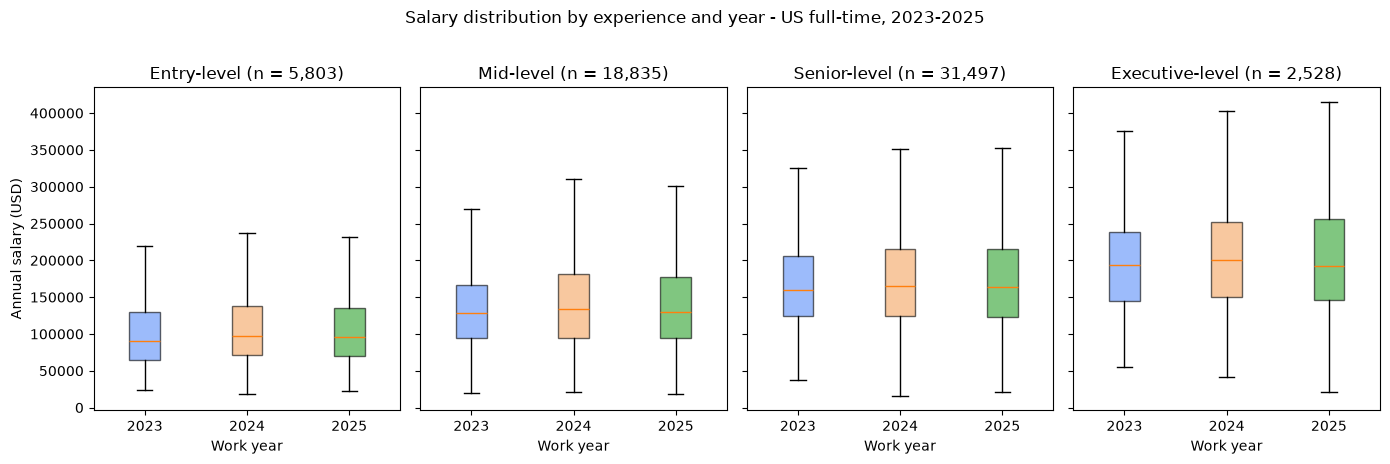


Outlier sensitivity (signed pct change = no_outlier - main; negative = median falls):
                            main_median  no_outlier_median  pct_change
work_year experience_level                                            
2023      EN                    90000.0            90000.0        0.00
          MI                   128000.0           127000.0       -0.78
          SE                   160374.0           160000.0       -0.23
          EX                   193250.0           185000.0       -4.27
2024      EN                    96800.0            96400.0       -0.41
          MI                   134000.0           132000.0       -1.49
          SE                   165000.0           162330.0       -1.62
          EX                   200000.0           190000.0       -5.00
2025      EN                    95510.0            95000.0       -0.53
          MI                   130000.0           129155.0       -0.65
          SE                   164000.0           160965.0   

In [10]:
# Objective 1 - salary distribution by experience and year
import matplotlib.pyplot as plt
import numpy as np

exp_order = ["EN", "MI", "SE", "EX"]
exp_labels = {"EN": "Entry-level", "MI": "Mid-level",
              "SE": "Senior-level", "EX": "Executive-level"}

# Reuse the Section 1.2 summary, but reordered so the experience axis reads EN -> EX.
summary_o1 = summary.reindex(exp_order, level="experience_level")
print("Salary (USD) by work year x experience level (US full-time, 2023-2025):")
print(summary_o1)

# Grouped boxplots, one panel per experience level, one box per year.
fig, axes = plt.subplots(1, 4, figsize=(14, 4.5), sharey=True)
year_palette = {2023: "#5B8FF9", 2024: "#F4A460", 2025: "#2CA02C"}
years = (2023, 2024, 2025)
for ax, lvl in zip(axes, exp_order):
    sub = ai_us[ai_us["experience_level"] == lvl]
    data = [sub.loc[sub["work_year"] == y, "salary_in_usd"].values for y in years]
    bp = ax.boxplot(data, tick_labels=list(years), patch_artist=True, showfliers=False)
    for patch, y in zip(bp["boxes"], years):
        patch.set_facecolor(year_palette[y]); patch.set_alpha(0.6)
    ax.set_title(f"{exp_labels[lvl]} (n = {len(sub):,})")
    ax.set_xlabel("Work year")
axes[0].set_ylabel("Annual salary (USD)")
fig.suptitle("Salary distribution by experience and year - US full-time, 2023-2025", y=1.02)
fig.tight_layout()
plt.show()

# Outlier sensitivity: medians with vs without salary_outlier_flag rows.
# pct_change is signed: a negative value means the median falls when flagged
# rows are removed, so the row labels stay aligned with the prose.
full_med = (ai_us.groupby(["work_year", "experience_level"])["salary_in_usd"]
            .median().round(0))
no_out_med = (ai_us.loc[~ai_us["salary_outlier_flag"]]
              .groupby(["work_year", "experience_level"])["salary_in_usd"]
              .median().round(0))
sens = pd.concat([full_med, no_out_med], axis=1)
sens.columns = ["main_median", "no_outlier_median"]
sens["pct_change"] = ((sens["no_outlier_median"] - sens["main_median"])
                      / sens["main_median"] * 100).round(2)
print("\nOutlier sensitivity (signed pct change = no_outlier - main; negative = median falls):")
print(sens.reindex(exp_order, level="experience_level"))

**Method and scope.** This objective uses the 58,663 full-time US records in `ai_us`, grouped by `experience_level` (EN, MI, SE, EX) and `work_year` (2023-2025). Headline numbers are annual-USD medians with the IQR; the figure is one boxplot per experience level with one box per year. The pre-existing `summary` table is reused, with experience reordered EN -> EX.

**Main experience result.** Median pay rises sharply with seniority. In 2024 the four medians are $96,800 (EN, n=2,623), $134,000 (MI, n=7,875), $165,000 (SE, n=12,139) and $200,000 (EX, n=752), an EN-to-EX spread of $103,200 (about 2.1x). IQRs overlap clearly: EN $137,750 vs MI $95,000; MI $181,000 vs SE $123,820; SE $215,166 vs EX $150,000. So medians differ cleanly while adjacent IQRs overlap heavily.

**Year pattern.** Within each experience level, medians are stable across 2023-2025. SE goes $160,374 to $165,000 to $164,000, a 2.3% rise; EX goes $193,250 to $200,000 to $192,300, oscillating under 4%. Group sizes are imbalanced: the 2023-to-2025 ratio is 6.6x for SE but 10.0-12.8x for the other three, a real year-to-year caveat.

**Robustness and limitations.** The sensitivity table reports the signed change in median after removing the 1,652 flagged rows; negative = median falls. The largest shift is EX 2024, where the median decreases by 5.00% (from $200,000 to $190,000); every other cell falls by less than 3% and EN by less than 0.5%. The seniority ladder and year-on-year stability both survive the check.

**Objective conclusion.** Salary is strongly stratified by experience and only mildly sensitive to work year. Differences are descriptive, not causal, and the dataset has no unique employee identifier, so rows are survey records, not unique people or vacancies.

$\large \color{royalblue} {\textbf{Objective 2 Analysis}}$ 

Work-mode counts by year:
work_mode  On-site  Hybrid  Remote
work_year                         
2023          2455      11    1305
2024         18091       6    5292
2025         23926       3    7574

Within-year work-mode percentage:
work_mode  On-site  Hybrid  Remote
work_year                         
2023          65.1     0.3    34.6
2024          77.3     0.0    22.6
2025          75.9     0.0    24.0

Salary (USD) by work mode:
               n    median        q1        q3
work_mode                                     
Hybrid        20  100000.0   85865.0  123250.0
On-site    44472  148600.0  106400.0  202000.0
Remote     14171  146600.0  106900.0  194000.0

On-site vs Remote medians within experience levels:
                  n_On-site  n_Remote  median_On-site  median_Remote  remote_minus_onsite
experience_level                                                                         
EN                     4696      1098         97723.0        90000.0              -7723.0
MI 

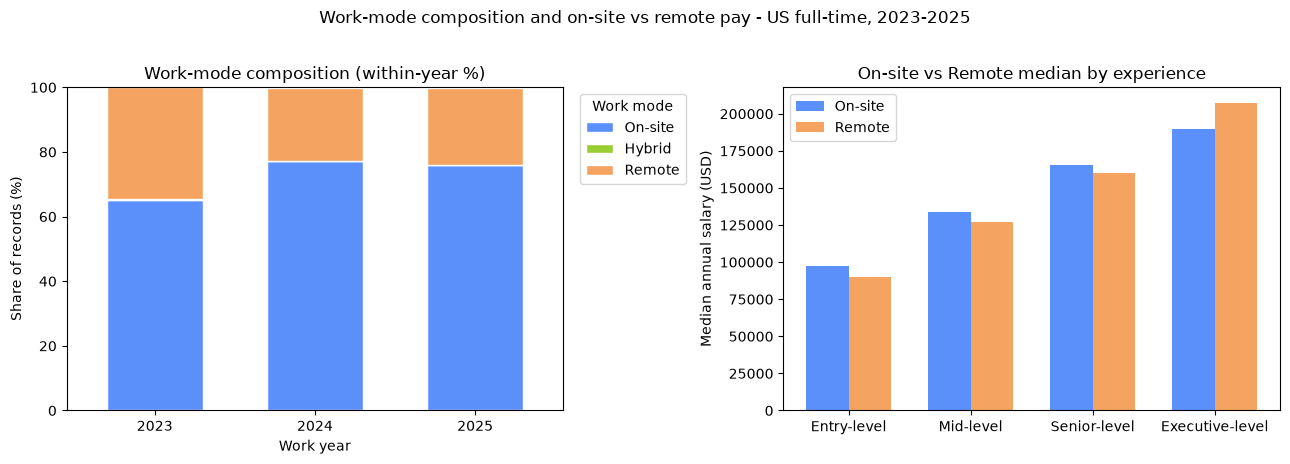

In [11]:
# Objective 2 - work-mode composition and on-site vs remote salary differences

# Composition: counts and within-year percentages, ordered On-site -> Hybrid -> Remote.
wm_counts = ai_us.groupby(["work_year", "work_mode"]).size().unstack(fill_value=0)
wm_counts = wm_counts[["On-site", "Hybrid", "Remote"]]
wm_pct = (wm_counts.div(wm_counts.sum(axis=1), axis=0) * 100).round(1)
print("Work-mode counts by year:")
print(wm_counts)
print("\nWithin-year work-mode percentage:")
print(wm_pct)

# Salary summary by work mode (median + IQR; mean is reported only as context).
def q25(s): return s.quantile(0.25)
def q75(s): return s.quantile(0.75)
sal_by_mode = (ai_us.groupby("work_mode")["salary_in_usd"]
               .agg(n="size", median="median", q1=q25, q3=q75).round(0))
print("\nSalary (USD) by work mode:")
print(sal_by_mode)

# On-site vs Remote within each experience level (Hybrid omitted from headline salary).
onrem = (ai_us[ai_us["work_mode"].isin(["On-site", "Remote"])]
         .groupby(["experience_level", "work_mode"])["salary_in_usd"]
         .agg(n="size", median="median").round(0).unstack())
onrem.columns = [f"{a}_{b}" for a, b in onrem.columns]
onrem["remote_minus_onsite"] = (onrem["median_Remote"] - onrem["median_On-site"]).round(0)
print("\nOn-site vs Remote medians within experience levels:")
print(onrem.reindex(exp_order))

# Cross-border sensitivity: recompute after dropping the 30 cross-border rows in ai_us.
ai_us_nocb = ai_us[ai_us["employee_residence"] == "US"]
sens_cb = (ai_us_nocb[ai_us_nocb["work_mode"].isin(["On-site", "Remote"])]
           .groupby(["experience_level", "work_mode"])["salary_in_usd"]
           .median().round(0).unstack())
sens_cb["remote_minus_onsite"] = (sens_cb["Remote"] - sens_cb["On-site"]).round(0)
print("\nCross-border sensitivity (Remote - On-site medians, no cross-border):")
print(sens_cb.reindex(exp_order))

# Two-panel figure: composition (left) and on-site vs remote within experience (right).
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
wm_pct.plot(kind="bar", stacked=True, ax=axes[0],
            color=["#5B8FF9", "#9ACD32", "#F4A460"], edgecolor="white", width=0.6)
axes[0].set_title("Work-mode composition (within-year %)")
axes[0].set_ylabel("Share of records (%)")
axes[0].set_xlabel("Work year")
axes[0].set_xticklabels([2023, 2024, 2025], rotation=0)
axes[0].legend(title="Work mode", bbox_to_anchor=(1.02, 1), loc="upper left")
axes[0].set_ylim(0, 100)

x = np.arange(len(exp_order))
w = 0.35
on_v = onrem["median_On-site"].reindex(exp_order)
re_v = onrem["median_Remote"].reindex(exp_order)
axes[1].bar(x - w/2, on_v, w, label="On-site", color="#5B8FF9")
axes[1].bar(x + w/2, re_v, w, label="Remote", color="#F4A460")
axes[1].set_xticks(x); axes[1].set_xticklabels([exp_labels[e] for e in exp_order])
axes[1].set_ylabel("Median annual salary (USD)")
axes[1].set_title("On-site vs Remote median by experience")
axes[1].legend()
fig.suptitle("Work-mode composition and on-site vs remote pay - US full-time, 2023-2025", y=1.02)
fig.tight_layout()
plt.show()

**Method and scope.** This objective uses the same 58,663 full-time US records. Composition is reported as within-year percentages of On-site, Hybrid and Remote, so each year sums to 100%. Salary comparisons use annual-USD medians with IQR, broken down within each experience level, to reduce the impact of different experience composition on the overall salary comparison.

**Composition result.** On-site dominates and the remote share fell sharply after 2023. Composition shifts from 65.1% On-site / 0.3% Hybrid / 34.6% Remote in 2023 to 77.3% / 0.0% / 22.6% in 2024 and 75.9% / 0.0% / 24.0% in 2025. The Remote share dropped 12.0 percentage points from 2023 to 2024 (1,305 to 5,292 remote records; full-time US records grew from 3,771 to 23,389). Hybrid is too rare for stable inference and is omitted from the salary analysis.

**Salary result.** Overall, On-site and Remote medians are close: $148,600 (n=44,472) and $146,600 (n=14,171), a $2,000 gap, with overlapping IQRs of $106,400-$202,000 and $106,900-$194,000. The Hybrid median of $100,000 (n=20) is unreliable due to its very small sample.

**Experience-level comparison.** Stratifying by experience reveals heterogeneity the overall figure masks. Remote minus On-site is -$7,723 at EN, -$6,370 at MI, -$5,296 at SE and +$17,445 at EX. EN, MI and SE remote records earn slightly less than on-site peers, but EX remote records earn $17,445 more. The overall near-parity is not a weighted average of group medians and hides heterogeneous gaps; sizes are imbalanced (SE 23,070 vs 8,423; EX 2,027 vs 500).

**Uncertainty and conclusion.** Dropping the 30 cross-border rows leaves within-experience Remote-minus-On-site medians essentially unchanged (e.g. EX $17,000 vs $17,445, SE -$5,296 unchanged). Conclusions are descriptive only: this voluntary survey cannot establish that work mode caused any observed pay difference.

$\large \color{royalblue} {\textbf{Section 1.4 – Part 1 Insights and Reflections (4 marks)}}$ 

**Synthesis.** Three findings stand out. (1) Salary rises sharply with experience: in 2024 the medians are $96,800 (EN), $134,000 (MI), $165,000 (SE) and $200,000 (EX), an EN-to-EX spread of $103,200 (about 2.1x), even though adjacent IQRs overlap heavily. (2) Pay is broadly stable across years: 2023-2025 median changes are +6.1% (EN), +1.6% (MI), +2.3% (SE) and -0.5% (EX), all within a single-digit percentage band. (3) The Remote share fell from 34.6% in 2023 to 22.6% in 2024, while the pooled 2023-2025 On-site and Remote medians are $148,600 and $146,600, a $2,000 gap.

**Unexpected result.** The pooled On-site vs Remote near-parity hides four heterogeneous experience-level gaps, with direction and magnitude both differing: EN, MI and SE remote records earn less than on-site peers, while EX remote records earn $17,445 more. This was checked by re-running within-experience medians on the 58,663 full-time US sample and again after dropping the 30 cross-border rows (EX gap moved only from $17,445 to $17,000).

**What the data can and cannot support.** Findings describe observed full-time US records from a voluntary survey, not the full AI/data workforce. Without population weights, unequal year sizes (3,771 in 2023 vs 23,389 in 2024) make year-to-year claims weak. The full-time restriction and rare Hybrid (n=20) limit generalisability. The analysis is descriptive only and cannot establish that work mode, year or experience caused any observed pay difference.


$\large \color{royalblue} {\textbf{Part 2: Machine Learning Pipeline (32 marks)}}$


$\large \color{royalblue} {\textbf{Dataset loading & exploration}}$ 


In [38]:
import pandas as pd

# Load the Part 2 dataset provided by the module team and explore its attributes
df = pd.read_csv('employee_churn_dataset.csv')
print(f"Loaded employee_churn_dataset.csv, shape: {df.shape}")
print(f"\nColumns and data type:\n{df.dtypes}")
print(f"\nFirst 3 rows of total {len(df)} rows\n:{df.head(3)}")

target_dist = pd.DataFrame({
    'count': df['churned'].value_counts(),
    'percetage(%)': df['churned'].value_counts(normalize=True).mul(100).round(2)
})

print(f"\nTarget variable(churned) counts and percentage:\n{target_dist}")

missing_report = pd.DataFrame({
    'missing_count':df.isna().sum(),
    'missing_pct(%)':(df.isna().sum() / len(df) * 100).round(2)
})
print(f"\nMissing values percetage per column:\n{missing_report}")

dup_report = pd.DataFrame({
    'duplicate_rows':[df.duplicated().sum()],
    'duplicate_employee_id':df['employee_id'].duplicated().sum()
})

Loaded employee_churn_dataset.csv, shape: (1020, 14)

Columns and data type:
employee_id                   int64
age                         float64
years_at_company            float64
salary                      float64
satisfaction_score          float64
engagement_index            float64
department                      str
contract_type                   str
education_level                 str
performance_rating              str
remote_work_level               str
favourite_colour                str
exit_interview_completed        str
churned                         str
dtype: object

First 3 rows of total 1020 rows
:   employee_id   age  years_at_company   salary  satisfaction_score  engagement_index   department contract_type education_level  \
0        10524  23.0               1.3  33069.0                 4.5         39.747809    Marketing     permanent        Bachelor   
1        10603  39.0               7.7  52024.0                 5.0         51.501357  Engineering     perm

$\large \color{royalblue} {\textbf{Section 2.1 – Preprocessing and Pipelines (10 marks)}}$ 


Prepare the dataset and build a scikit-learn preprocessing pipeline. After the code, write a brief reflection explaining the decisions you made

In [ ]:
# Section 2.1 coding plan — complete and adapt each step using your own decisions
# 1. Confirm the cleaned Part 2 dataframe and the target column.
# 2. Remove only the verified complete duplicate rows before splitting.
# 3. Define the prediction target and separate y from the predictor dataframe X.
# 4. Exclude identifier-like, post-outcome or otherwise unjustified features,
#    documenting the reasons in the markdown reflection below.
# 5. Apply deterministic department cleaning (trim whitespace and standardise case).
# 6. Create a reproducible stratified train/test split before fitting any learned
#    imputer, encoder or scaler. Print the resulting shapes and class proportions.
# 7. Identify the numerical and categorical predictor columns explicitly.
# 8. Build a numerical transformer: training-fold imputation and, if justified
#    by the selected classifiers, scaling.
# 9. Build a categorical transformer: training-fold imputation and encoding that
#    can handle categories not observed during training.
# 10. Combine both branches with a ColumnTransformer.
# 11. Fit the preprocessor on X_train only and check the transformed shape and
#     missing-value status. Later models must reuse this logical preprocessor
#     inside complete sklearn Pipelines.
# 12. Record the actual choices and outputs before writing the 200–250 word
#     preprocessing reflection.

# Write your implementation below. Do not fit preprocessing on the full dataset.
# 导入 pandas、train_test_split、
# Pipeline、ColumnTransformer、
# SimpleImputer、StandardScaler、
# OneHotEncoder

# 复制数据，避免直接修改原始数据
part2_data = ...

# 删除完整重复行
part2_data = ...

# 设置目标变量和预测变量
y = ...
X = ...

# 根据你的预测时点决定排除的变量
X = ...

# 清理 department 的空格和大小写
X["department"] = ...

# 分层划分训练集和测试集
X_train, X_test, y_train, y_test = ...

# 明确列出数值变量和分类变量
numeric_features = [...]
categorical_features = [...]

# 数值分支：缺失值填补；是否标准化要结合模型需求决定
numeric_transformer = Pipeline(steps=[
    # ("imputer", ...),
    # ("scaler", ...)
])

# 分类分支：缺失值填补 + 独热编码
categorical_transformer = Pipeline(steps=[
    # ("imputer", ...),
    # ("encoder", ...)
])

# 合并两个分支
preprocessor = ColumnTransformer(
    transformers=[
        # ("num", numeric_transformer, numeric_features),
        # ("cat", categorical_transformer, categorical_features)
    ]
)

# 只用训练集拟合并转换
X_train_transformed = ...
X_test_transformed = ...

# 检查转换结果
print(...)

**Preprocessing reflection:**

Write your reflection on the preprocessing decisions you made, grounded in your specific dataset.

_Expected length: approximately 200-250 words_

_[Write your response here]_

$\large \color{royalblue} {\textbf{Section 2.2 – Baseline Model Training (4 marks)}}$ 


Train two classification models as baselines. For each model, build a complete pipeline that incorporates your preprocessor. After the code, justify your choice of classifiers.

Train Model 1 below, then Model 2 in the cell that follows.

In [14]:
# Define Model 1
# clf1 = ...



**Model 2 – Baseline** 

In [15]:
# Define Model 2 (must be a different algorithm from Model 1)
# clf2 = ...


**Baseline model rationale**

Briefly explain why the two selected classifiers are appropriate for this classification task and how they differ in their underlying approach.

_Expected length: approximately 100–150 words_

_[Write your response here]_

$\large \color{royalblue} {\textbf{Section 2.3 – Cross-Validation (6 marks)}}$ 

Evaluate both baseline pipelines using cross-validation. Report at least one metric beyond accuracy. After the code, reflect on what the results tell you and which model you would take forward.

In [16]:

# Cross-validate Model 1 (full pipeline)
# scoring: choose metrics relevant to your problem


In [17]:
# Cross-validate Model 2 (full pipeline)


In [18]:
# Produce a summary comparison of cross-validation scores for both models


**Cross-validation reflection:**

Write a short reflection comparing the cross-validation results for both models and discussing what they indicate about performance and stability. Identify which model you have selected for hyperparameter tuning and justify your decision using the results.

_Expected length: approximately 200–250 words_

_[Write your response here]_

$\large \color{royalblue} {\textbf{Section 2.4 – Hyperparameter Tuning (6 marks)}}$ 


Select one model to tune. Apply a hyperparameter search to the full pipeline and report the best configuration found. Compare the tuned performance with your baseline results from Section 2.3.

In [19]:

# Choose which model to tune and justify the choice in the reflection below
# model_to_tune = model1  # or model2



In [20]:
# Report the best parameters and best cross-validation score
# Compare the tuned cross-validation results with the baseline results 

**Hyperparameter tuning reflection:**

Write a short reflection on your tuning decisions and results. Justify the model and scoring metric selected, and compare the tuned cross-validation performance with the baseline cross-validation results from Section 2.3.

_Expected length: approximately 200–250 words_

_[Write your response here]_

$\large \color{royalblue} {\textbf{Section 2.5 – Final Model Evaluation and Justification (6 marks)}}$ 

Evaluate your final model on the held-out test set. Report appropriate metrics and display a confusion matrix. Compare the test performance with your earlier cross-validation results and provide a justified recommendation

In [21]:
# Evaluate the tuned model on the held-out test set
# Display the classification metrics, confusion matrix and classification report
# Summarise the baseline CV, tuned CV and final test results

**Final Model Evaluation and Justification**

Evaluate the final model's performance, drawing on specific values from the confusion matrix, classification report and cross-validation results. Discuss whether the model generalises well and provide a reasoned recommendation.

_Expected length: approximately 250–300 words_

_[Write your response here]_

$\large \color{royalblue} {\textbf{Process Log (12 marks)}}$ 

Answer all three of the following.

**1. Dead ends:** Describe at least two things you tried that did not work, one from Part 1 and one from Part 2. Be specific about what you tried, what happened, and what you changed as a result.

**2. What surprised you:** Identify one finding from your analysis that 
genuinely surprised you. Reference the specific value or output that 
surprised you and explain why it was unexpected.

**3. What you would do differently:** If you were starting this project again 
with more time, what is the one thing you would do differently? Ground your 
answer in your own results, not a generic comment about machine learning.


_Expected length: approximately 350-400 words_

_[Write your response here]_

## Notebook Word Count Code

The cell below counts the total markdown words and code lines across your whole notebook. Ensure you have deleted all template placeholder and instructional text before running it, this count includes any instructional text you haven't removed yet.

**Limits:**
- Maximum 600 lines of code (combined across Part 1 and Part 2)
- Maximum 3800 markdown words (combined across Part 1, Part 2, and the Process Log)

Submissions that exceed these limits may lose marks for a lack of conciseness.

In [22]:
# Please do not delete this cell
import json

def count_notebook_stats(path, exclude_last_cell=True):
    with open(path, 'r', encoding='utf-8') as f:
        nb = json.load(f)

    # Excludes this cell itself, so the tool's own code isn't counted
    # as part of your code line total.
    cells = nb['cells'][:-1] if exclude_last_cell else nb['cells']

    markdown_words = 0
    code_lines = 0

    for cell in cells:
        src = ''.join(cell['source'])

        if cell['cell_type'] == 'markdown':
            markdown_words += len(src.split())

        elif cell['cell_type'] == 'code':
            code_lines += len([
                l for l in src.split('\n')
                if l.strip() and not l.strip().startswith('#')
            ])

    return markdown_words, code_lines

md_words, code_lines = count_notebook_stats('P4DS_A2_Data_Analysis_Project.ipynb')
print("Markdown words:", md_words)
print("Code lines:    ", code_lines)

Markdown words: 2794
Code lines:     204
